<a href="https://colab.research.google.com/github/sylle321/Hotel_booking/blob/main/Descriptive_question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm import tqdm

path = "/content/hotels.csv"
df = pd.read_csv(path)
#Shows each columns data type and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Counts distinct values in each column of the dataframe.
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [ ]:
# Convert hotel to a dummy variable:
# Resort Hotel = 0, City Hotel = 1
df['hotel'] = df['hotel'].map({
    'Resort Hotel': 0,
    'City Hotel': 1
})

df.head()

# Create dummy variables for the other categorical variables
categorical_cols = [
    'deposit_type',
    'market_segment',
    'customer_type',
    'reserved_room_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
# Selecting the columns of interest for analysis
# Making sure unrelated columns are not included in the analysis.
cols = [
    "hotel",
    "is_canceled",
    "lead_time",
    "deposit_type",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "customer_type",
    "booking_changes",
    "is_repeated_guest",
    "market_segment",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "reserved_room_type",
    "adr",
    "distribution_channel",
    "arrival_date_month"
]

hotel_selected = df[cols]

hotel_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   deposit_type                    119390 non-null  object 
 4   previous_cancellations          119390 non-null  int64  
 5   previous_bookings_not_canceled  119390 non-null  int64  
 6   customer_type                   119390 non-null  object 
 7   booking_changes                 119390 non-null  int64  
 8   is_repeated_guest               119390 non-null  int64  
 9   market_segment                  119390 non-null  object 
 10  total_of_special_requests       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [ ]:
#Cleaning the data by removing rows with any missing values and resetting the index.
hotel_clean = hotel_selected.dropna(how="any") #Removes rows with any missing values.
hotel_clean = hotel_clean.reset_index(drop=True) #resets the index

print(hotel_selected.shape)
print(hotel_clean.shape)

(119390, 17)
(119390, 17)


In [ ]:
#Checking cancelation counts and proportions in the cleaned dataset.
print(hotel_clean["is_canceled"].value_counts()) #Gives the count of each unique value in the "is_canceled" column.

print(
    hotel_clean["is_canceled"].value_counts(normalize=True) # Gives the proportion of each unique value in the "is_canceled" column.
)


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


In [ ]:
# Calculate the correlation using PCA lab's code as reference.
# We exclude categorical string columns and only keep truly numeric columns
numeric_cols = [
    "is_canceled",
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

hotel_numeric = hotel_clean[numeric_cols]

corr_mat = hotel_numeric.corr()

corr_mat.round(4)

,is_canceled,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
is_canceled,1.0000,0.2931,0.1101,-0.0574,-0.1444,-0.0848,-0.2347,-0.0018,0.0248,0.0476
lead_time,0.2931,1.0000,0.0860,-0.0735,0.0001,-0.1244,-0.0957,0.0857,0.1658,-0.0631
previous_cancellations,0.1101,0.0860,1.0000,0.1527,-0.0270,0.0823,-0.0484,-0.0128,-0.0140,-0.0656
previous_bookings_not_canceled,-0.0574,-0.0735,0.1527,1.0000,0.0116,0.4181,0.0378,-0.0427,-0.0487,-0.0721
booking_changes,-0.1444,0.0001,-0.0270,0.0116,1.0000,0.0121,0.0528,0.0633,0.0962,0.0196
is_repeated_guest,-0.0848,-0.1244,0.0823,0.4181,0.0121,1.0000,0.0131,-0.0872,-0.0972,-0.1343
total_of_special_requests,-0.2347,-0.0957,-0.0484,0.0378,0.0528,0.0131,1.0000,0.0727,0.0682,0.1722
stays_in_weekend_nights,-0.0018,0.0857,-0.0128,-0.0427,0.0633,-0.0872,0.0727,1.0000,0.4990,0.0493
stays_in_week_nights,0.0248,0.1658,-0.0140,-0.0487,0.0962,-0.0972,0.0682,0.4990,1.0000,0.0652
adr,0.0476,-0.0631,-0.0656,-0.0721,0.0196,-0.1343,0.1722,0.0493,0.0652,1.0000


In [ ]:
# Correlation with is_canceled only
corr_mat[["is_canceled"]].round(3)

,is_canceled
is_canceled,1.000
lead_time,0.293
previous_cancellations,0.110
previous_bookings_not_canceled,-0.057
booking_changes,-0.144
is_repeated_guest,-0.085
total_of_special_requests,-0.235
stays_in_weekend_nights,-0.002
stays_in_week_nights,0.025
adr,0.048


In [ ]:
# Separate the target variable from the predictor variables
knn_cols = hotel_numeric

X = knn_cols.drop(columns=["is_canceled"])
y = knn_cols["is_canceled"]

# Split the data into 80% training and 20% testing
# stratify maintains the same cancellation proportion in both sets
# random_state ensures the split is reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Check the size of each dataset
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (95512, 9)
Testing set: (23878, 9)


1 0.7790853505318703
2 0.7979311500125639
3 0.7853254041377
4 0.7973448362509423
5 0.7926543261579697
6 0.7983080660021777
7 0.7947483038780467
8 0.7959209314012899
9 0.7948320629868498
10 0.7962559678365022
11 0.7934081581371975
12 0.794455146997236
13 0.7941201105620236
14 0.7943295083340314
15 0.7932825194739928
16 0.7923192897227573
17 0.7911047826451126
18 0.7926124466035681
19 0.7921098919507497
20 0.7911466621995142
21 0.7911885417539157
22 0.7902253120026803
23 0.789974034676271
24 0.7900996733394756
25 0.7886757684898232
26 0.7886757684898232
27 0.7887595275986263
28 0.7869168272049586
29 0.7873775023033754
30 0.7866236703241477


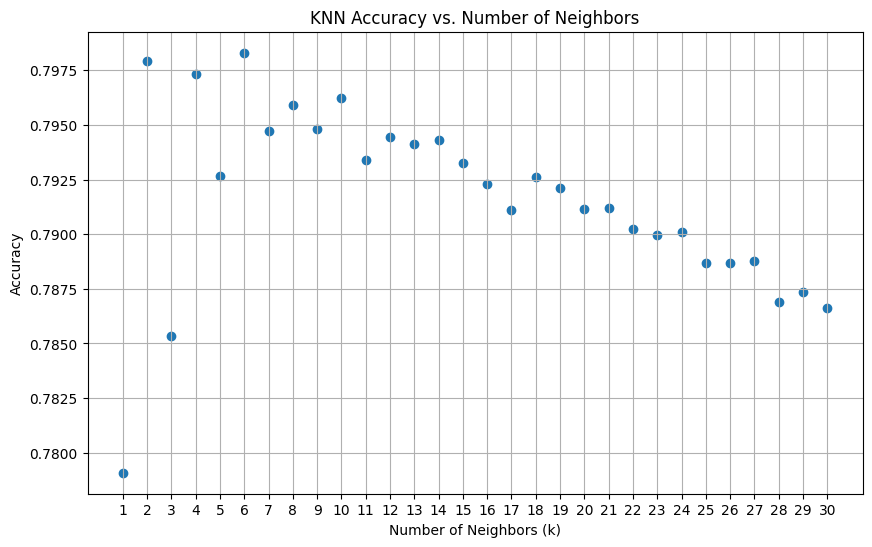

Best k: 6
Highest accuracy: 0.7983080660021777
Accuracy: 0.7866236703241477
Confusion Matrix:
[[13709  1324]
 [ 3771  5074]]


In [ ]:
# Learn means and standard deviations from the training set
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Find the best number of neighbors
k_values = range(1, 31)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    accuracy = accuracy_score(y_test, knn.predict(X_test_scaled))
    accuracies.append(accuracy)
    print(k, accuracy)

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(k_values, accuracies)

plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. Number of Neighbors')
plt.xticks(range(1, 31))
plt.grid(True)
plt.show()

print("Best k:", k_values[accuracies.index(max(accuracies))])
print("Highest accuracy:", max(accuracies))


# Predict hotel booking cancellations
y_pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
